# Baseline model interpretation

Per-model prediction plots and official-metric scores, on one split, with one grader.

Each baseline gets a section: what it is, a prediction-vs-actual figure over a fixed set
of windows and turbines, then RMSE / MAE / competition score from the **official** Baidu
grader. After the baselines there are cross-model sections: every model on one axes, the
farm aggregate, error against horizon, the degeneracy guards, and the summary.

**Split-aware artifacts.** Every fitted baseline exists twice, once per split:

| model | validation split (`SPLIT = "val"`) | test split (`SPLIT = "test"`) |
|---|---|---|
| ARMA | `baselines/classical/arma_val.joblib` | `baselines/classical/arma_full.joblib` |
| XGBoost | `baselines/tree/gbdt_val.joblib` | `baselines/tree/gbdt_full.joblib` |
| GRU | `baselines/gru/ckpt_val/` | `baselines/gru/ckpt_full/` |

`_val` is fitted on days 1–197 and scored on the 24 windows from days 198–245.
`_full` is fitted on all 245 days and scored on `final_phase_test` (142 windows).

Using a `_full` artifact on the validation split would be **leakage** — it was fitted on
the very days it would then be scored on. The setup cell binds the artifact set to
`SPLIT` for exactly that reason, and refuses to guess.


## 1 · Setup

Imports the project's own modules rather than re-deriving any of them:

- `paths.py` — every filesystem location
- `evaluation/evaluator.py` — the validation-split scorer (official grader inside)
- `evaluation/competition_score.py` — the locked test-set scorer
- `evaluation/official_metrics.py` — the verbatim Baidu grader, used directly for the guard section

Set `SPLIT` here and everything downstream follows: which windows are scored, which
training file `forecast()` is handed, and which fitted artifacts are loaded.


In [9]:
import os, sys, glob, io, time, json, importlib, importlib.util, contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- repo root --------------------------------------------------------------
REPO = os.environ.get("WINDEVOLVE_REPO", "")
if not os.path.isdir(REPO):
    REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "windevolve_sdwpf"))
if not os.path.isdir(REPO):
    REPO = os.path.expanduser("~/srip/windevolve_sdwpf")
for sub in ["", "evaluation", "analysis",
            "baselines/naive", "baselines/classical", "baselines/tree", "baselines/gru"]:
    p = os.path.join(REPO, sub)
    if p not in sys.path:
        sys.path.insert(0, p)

# --- which split ------------------------------------------------------------
# "val"  -> 24 windows on days 198-245, scored by evaluator.py. The default, and the
#           only split the search arms are ever allowed to see.
# "test" -> the locked 142-window final_phase_test, scored by competition_score.py.
#           Spend it once, on a program declared final beforehand.
SPLIT = "val"
N_WINDOWS = None          # None = every window of the chosen split

import paths as P
import evaluator as EV
import competition_score as CS
import official_metrics as OM
from test_data import TestData

CAPACITY, HORIZON, DAY_LEN = EV.CAPACITY, EV.OUTPUT_LEN, EV.DAY_LEN

# --- fitted artifacts, bound to the split -----------------------------------
# _val  : fitted on days 1-197,  scored on the 24 validation windows
# _full : fitted on all 245 days, scored on final_phase_test (142 windows)
# Mixing them is leakage, so this mapping is the single place the choice is made.
# Every baseline reads its path from these env vars AT IMPORT TIME, which is why they
# are set before any baseline is imported.
BASE = P.BASELINES_DIR
ARTIFACTS = {
    "val": {
        "SDWPF_ARIMA_MODEL":     os.path.join(BASE, "classical", "arma_val.joblib"),
        "SDWPF_GBDT_MODEL":      os.path.join(BASE, "tree", "gbdt_val.joblib"),
        "SDWPF_GRU_CHECKPOINTS": os.path.join(BASE, "gru", "ckpt_val"),
    },
    "test": {
        "SDWPF_ARIMA_MODEL":     os.path.join(BASE, "classical", "arma_full.joblib"),
        "SDWPF_GBDT_MODEL":      os.path.join(BASE, "tree", "gbdt_full.joblib"),
        "SDWPF_GRU_CHECKPOINTS": os.path.join(BASE, "gru", "ckpt_full"),
    },
}
for k, v in ARTIFACTS[SPLIT].items():
    os.environ[k] = v

SPLIT_DIR = P.VAL_DIR if SPLIT == "val" else P.TEST_DIR
infiles = sorted(glob.glob(os.path.join(SPLIT_DIR, "infile", "*in.csv")))
outfiles = sorted(glob.glob(os.path.join(SPLIT_DIR, "outfile", "*out.csv")))

# --- what to plot -----------------------------------------------------------
# The SAME windows and turbines for every model, so the per-model figures are
# directly comparable. 0-based internally, printed 1-based.
WINDOWS = [0, 11, 23] if SPLIT == "val" else [0, 70, 141]
TURBINES = [0, 42, 97]
SHOW_TURBINE, SHOW_WINDOW = TURBINES[0], WINDOWS[0]

np.random.seed(1)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NAVY, GOLD, RUST, TEAL = "#3C3489", "#C8A227", "#D85A30", "#1D9E75"
COLOURS = {"Seasonal naive": "#d62728", "Climatology": "#ff7f0e", "ARMA(1,0,1)": "#2ca02c",
           "XGBoost": "#1f77b4", "GRU": "#9467bd", "aug5b champion": "#17becf",
           "actual": "#111111"}

# Published references (Zhou et al., Scientific Data 11:649, 2024, Fig. 3). Both are on
# the 142-window TEST set, so they are comparable ONLY when SPLIT == "test".
PUBLISHED_GRU = 47.850
PUBLISHED_BEST_TEAM = 44.917      # HIK, 1st place

print("repo        :", REPO)
print("split       :", SPLIT, "->", SPLIT_DIR)
print("windows     :", len(infiles))
print("train file  :", P.VAL_TRAIN_FILE if SPLIT == "val" else P.TRAIN_FILE)
print("plotting    : windows", [w + 1 for w in WINDOWS], " turbines", TURBINES)
print("\nartifacts for this split:")
for k, v in ARTIFACTS[SPLIT].items():
    print("  {:<24} {}  [{}]".format(k, v, "ok" if os.path.exists(v) else "MISSING"))
if SPLIT == "test":
    print("\nNOTE: this is the LOCKED test set. Score it once, on a declared-final program.")


repo        : /home/dorsa/srip/windevolve_sdwpf
split       : val -> /home/dorsa/srip/windevolve_sdwpf/evaluation/splits/val_windows
windows     : 24
train file  : /home/dorsa/srip/windevolve_sdwpf/evaluation/splits/val_train.csv
plotting    : windows [1, 12, 24]  turbines [0, 42, 97]

artifacts for this split:
  SDWPF_ARIMA_MODEL        /home/dorsa/srip/windevolve_sdwpf/baselines/classical/arma_val.joblib  [ok]
  SDWPF_GBDT_MODEL         /home/dorsa/srip/windevolve_sdwpf/baselines/tree/gbdt_val.joblib  [ok]
  SDWPF_GRU_CHECKPOINTS    /home/dorsa/srip/windevolve_sdwpf/baselines/gru/ckpt_val  [ok]


## 2 · Helpers

Two groups: scoring (masking, prediction, the official grader) and figures.

`score_model` dispatches on `SPLIT`. On `"val"` it calls `evaluator._score_forecaster`,
the same function the search arms are scored by. On `"test"` it calls
`competition_score.score`, which loads the module's **file** — so any configuration
applied to a module object in this notebook is not seen there, only the file's defaults
and the `SDWPF_*` environment variables. That is flagged rather than silently ignored.


In [10]:
# --- masking and ground truth ----------------------------------------------
def masked_truth(raw_df):
    # Apply the OFFICIAL masking rules to one turbine-window, copied from
    # official_metrics.turbine_scores():
    #   drop if  any NaN in the row
    #         OR Patv < 0                       <- ALL negatives, unconditionally
    #         OR (Patv == 0 AND Wspd > 2.5)     <- stopped turbine in usable wind
    #         OR any Pab* > 89                  <- blades feathered
    #         OR |Wdir| > 180 OR |Ndir| > 720   <- sensor out of range
    # Same rule analysis/plots.ground_truth() applies, so notebook figures and report
    # figures shade identically.
    r = raw_df.reset_index(drop=True)
    nan_cond = pd.isna(r).any(axis=1)
    invalid = ((r["Patv"] < 0)
               | ((r["Patv"] == 0) & (r["Wspd"] > 2.5))
               | (r["Pab1"] > 89) | (r["Pab2"] > 89) | (r["Pab3"] > 89)
               | (r["Wdir"] < -180) | (r["Wdir"] > 180)
               | (r["Ndir"] < -720) | (r["Ndir"] > 720))
    keep = (~nan_cond & ~invalid).to_numpy()
    return r["Patv"].to_numpy(dtype=float), keep


def prep_env(infile):
    # envs dict for forecast(), from the scorer that matches the split: VAL_TRAIN_FILE on
    # validation, the full 245-day CSV on test -- exactly as when the model is scored.
    return EV._prep_env(infile) if SPLIT == "val" else CS._prep_env(infile)


_TRUTH_CACHE = {}

def truth_window(widx):
    # (truth, keep) for a whole window: two (134, 288) arrays. Cached.
    if widx not in _TRUTH_CACHE:
        td = TestData(path_to_data=outfiles[widx], start_col=3, farm_capacity=CAPACITY)
        _, raws = td.get_all_turbines()
        truth = np.full((CAPACITY, HORIZON), np.nan)
        keep = np.zeros((CAPACITY, HORIZON), dtype=bool)
        for t in range(CAPACITY):
            truth[t], keep[t] = masked_truth(raws[t].iloc[:HORIZON])
        _TRUTH_CACHE[widx] = (truth, keep)
    return _TRUTH_CACHE[widx]


_PRED_CACHE = {}

def predict_window(name, module, widx):
    # A model's (134, 288) forecast in kW for one window. Cached by (name, window).
    key = (name, widx)
    if key not in _PRED_CACHE:
        preds = np.asarray(module.forecast(prep_env(infiles[widx])), dtype=float)
        _PRED_CACHE[key] = preds.reshape(CAPACITY, HORIZON)
    return _PRED_CACHE[key]


# --- scoring ----------------------------------------------------------------
def score_model(module, n_windows=N_WINDOWS, quiet=True):
    # Score a LOADED baseline through the official grader on the chosen split.
    # Never raises: a MetricsError here is a degeneracy guard firing, which is a real
    # outcome, not a bug -- it comes back as valid=False with a reason.
    t0 = time.perf_counter()
    buf = io.StringIO()
    try:
        if SPLIT == "val":
            res = EV._score_forecaster(module, P.VAL_DIR, n_windows=n_windows)
        else:
            with contextlib.redirect_stdout(buf if quiet else sys.stdout):
                res = CS.score(module.__file__, test_dir=P.TEST_DIR, n_windows=n_windows)
            res["rmse"], res["mae"] = res["total_rmse"], res["total_mae"]
        res["valid"] = True
        res["reason"] = ""
    except Exception as e:
        res = {"valid": False, "reason": "{}: {}".format(type(e).__name__, str(e)[:160]),
               "competition_score": float("nan"), "rmse": float("nan"),
               "mae": float("nan"), "n_windows": 0}
    res["eval_seconds"] = time.perf_counter() - t0
    res["grader_log"] = buf.getvalue()
    res["comparable"] = bool(res["valid"])
    if SPLIT == "test":
        if n_windows is not None and n_windows != CS.NUM_MAX_RUNS:
            res["comparable"] = False
        if res["valid"] and res["competition_score"] == 65535:
            res["comparable"] = False
            res["reason"] = "official 65535 sentinel: incomplete run"
    return res


def score_model_draws(module, n_draws=5, n_windows=N_WINDOWS, seed_env=None):
    # Score a STOCHASTIC model several times and summarise. Only meaningful with
    # SDWPF_GRU_INFER_DROPOUT=1, which reproduces the official predict.py (it never calls
    # eval()). With the current default the GRU is deterministic and every draw is equal.
    saved = os.environ.get(seed_env) if seed_env else None
    scores, res = [], None
    for s in range(1, n_draws + 1):
        if seed_env:
            os.environ[seed_env] = str(s)
            importlib.reload(module)
        r = score_model(module, n_windows=n_windows)
        if not r["valid"]:
            return r
        scores.append(r["competition_score"])
        res = r
    if seed_env:
        if saved is None:
            os.environ.pop(seed_env, None)
        else:
            os.environ[seed_env] = saved
    res["score_draws"] = scores
    res["competition_score"] = float(np.mean(scores))
    res["score_std"] = float(np.std(scores, ddof=1)) if len(scores) > 1 else 0.0
    return res


def report_score(name, res):
    # Print the farm-level OFFICIAL competition score for a model.
    if not res.get("valid"):
        print("{:<22} FAILED - {}".format(name, res.get("reason", "unknown")))
        return res
    spread = ""
    if "score_std" in res:
        spread = " +/- {:.3f} ({} draws)".format(res["score_std"], len(res["score_draws"]))
    extra = ""
    if "accuracy" in res:
        extra = "  acc {:.1f}%".format(100 * res["accuracy"])
    elif "latest_rmse" in res:
        extra = "  last-24h RMSE {:.3f}".format(res["latest_rmse"])
    flag = "" if res.get("comparable") else "   [NOT leaderboard-comparable]"
    print("{:<22} RMSE {:.3f}  MAE {:.3f}  score {:.3f}{} MW{}  ({} windows, {:.0f}s){}".format(
        name, res["rmse"], res["mae"], res["competition_score"], spread, extra,
        res["n_windows"], res.get("eval_seconds", 0), flag))
    return res


MODULES = {}          # name -> loaded module
RESULTS = {}          # name -> official result dict
print("scoring helpers ready - {} split via {}".format(
    SPLIT, "evaluator.py" if SPLIT == "val" else "competition_score.py"))


scoring helpers ready - val split via evaluator.py


In [11]:
# --- figures ----------------------------------------------------------------
# Every per-model figure uses the SAME windows and turbines, so the panels on the model
# slides are directly comparable. PNGs land in FIG_DIR, ready to drop into the deck.
FIG_DIR = os.path.join(P.RUNS_DIR, "plots", "notebook", SPLIT)
os.makedirs(FIG_DIR, exist_ok=True)
HOURS = np.arange(HORIZON) * 10 / 60.0


def savefig(fig, name):
    path = os.path.join(FIG_DIR, name + ".png")
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    print("saved:", path)
    return path


def _slug(name):
    out = name.lower()
    for ch in " (),":
        out = out.replace(ch, "_" if ch == " " else "")
    return out


def shade_mask(ax, keep_row):
    # Grey out the contiguous runs of steps the official mask excludes from scoring.
    bad = ~keep_row
    i = 0
    while i < HORIZON:
        if bad[i]:
            j = i
            while j + 1 < HORIZON and bad[j + 1]:
                j += 1
            ax.axvspan(HOURS[i], HOURS[min(j + 1, HORIZON - 1)],
                       color="#BFBFBF", alpha=0.35, lw=0)
            i = j + 1
        else:
            i += 1


def show_prediction(module, name, tid=None, widx=None):
    # One turbine, one window, predicted vs actual, with the masked steps marked.
    tid = SHOW_TURBINE if tid is None else tid
    widx = SHOW_WINDOW if widx is None else widx
    truth, keep = truth_window(widx)
    pred = predict_window(name, module, widx)[tid]
    plt.figure()
    shade_mask(plt.gca(), keep[tid])
    plt.plot(HOURS, truth[tid] / 1000, color=NAVY, lw=1.6, label="actual")
    plt.plot(HOURS, pred / 1000, color=RUST, lw=1.6, label="predicted")
    plt.xlabel("hours ahead"); plt.ylabel("power (MW)")
    plt.title("{} - turbine {}, window {} ({} of {} steps scored)".format(
        name, tid, widx + 1, int(keep[tid].sum()), HORIZON))
    plt.xlim(0, 48); plt.legend(); plt.tight_layout(); plt.show()

    m = keep[tid]
    e = (pred[m] - truth[tid][m]) / 1000.0
    if e.size:
        rmse, mae = float(np.sqrt((e ** 2).mean())), float(np.abs(e).mean())
        print("this turbine/window: RMSE {:.4f}  MAE {:.4f}  score {:.4f} MW  "
              "({} of {} steps scored, {} masked)".format(
                  rmse, mae, 0.5 * (rmse + mae), m.sum(), HORIZON, (~m).sum()))
    else:
        print("every step masked in this turbine/window - nothing scored here")


def show_model_grid(name, module=None, windows=None, turbines=None, save=True):
    # ONE model against the truth, tiled over the SHARED windows x turbines. This is the
    # figure that goes on that model's slide. Using the same windows and turbines for
    # every model is the point: a single cherry-picked panel proves nothing, and panels
    # drawn from different windows cannot be compared side by side.
    module = module or MODULES[name]
    windows = WINDOWS if windows is None else windows
    turbines = TURBINES if turbines is None else turbines
    nrow, ncol = len(windows), len(turbines)
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 2.5 * nrow),
                             squeeze=False, sharex=True)
    for r, w in enumerate(windows):
        truth, keep = truth_window(w)
        pred = predict_window(name, module, w)
        for c, t in enumerate(turbines):
            ax = axes[r][c]
            shade_mask(ax, keep[t])
            ax.plot(HOURS, truth[t] / 1000, color=COLOURS["actual"], lw=1.6, zorder=6)
            ax.plot(HOURS, pred[t] / 1000, color=COLOURS.get(name, RUST), lw=1.4)
            ax.set_xlim(0, 48); ax.set_xticks([0, 12, 24, 36, 48])
            ax.grid(alpha=0.25, lw=0.5)
            if r == 0:
                ax.set_title("turbine {}".format(t), fontsize=10)
            if c == 0:
                ax.set_ylabel("window {}\npower (MW)".format(w + 1), fontsize=9)
            if r == nrow - 1:
                ax.set_xlabel("hours ahead", fontsize=9)
    handles = [plt.Line2D([], [], color=COLOURS["actual"], lw=1.6, label="actual"),
               plt.Line2D([], [], color=COLOURS.get(name, RUST), lw=1.6, label=name),
               plt.Rectangle((0, 0), 1, 1, color="#BFBFBF", alpha=0.35, label="masked")]
    fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=9,
               frameon=False, bbox_to_anchor=(0.5, 1.01))
    fig.suptitle("{} - forecast vs actual ({} split)".format(name, SPLIT),
                 y=0.965, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    if save:
        savefig(fig, "pred_" + _slug(name))
    plt.show()


print("figure helpers ready - PNGs ->", FIG_DIR)


figure helpers ready - PNGs -> /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val


## 3 · Baselines

One section per model: plot first, score second, with the reading of each result in the
`# Analysis:` comment under the score.


### 3.1 · Seasonal naive

Copies a fixed block of recent history forward until the 48 h horizon is filled.
No fitting, no artifact — the floor everything else is measured against.

`LAG` defaults to `3 * DAY_LEN = 432` in the baseline itself: the 48 h block ending one
day ago, which was the best setting on the sweep. It is deliberately **not** 144 (daily
seasonal naive), because copying the previous 24 h forward produces an all-zero forecast
for every parked turbine and the official zero-prediction guard rejects the window.
Override with `SDWPF_NAIVE_LAG` if you want to reproduce that.


LAG = 432 steps (72 h)


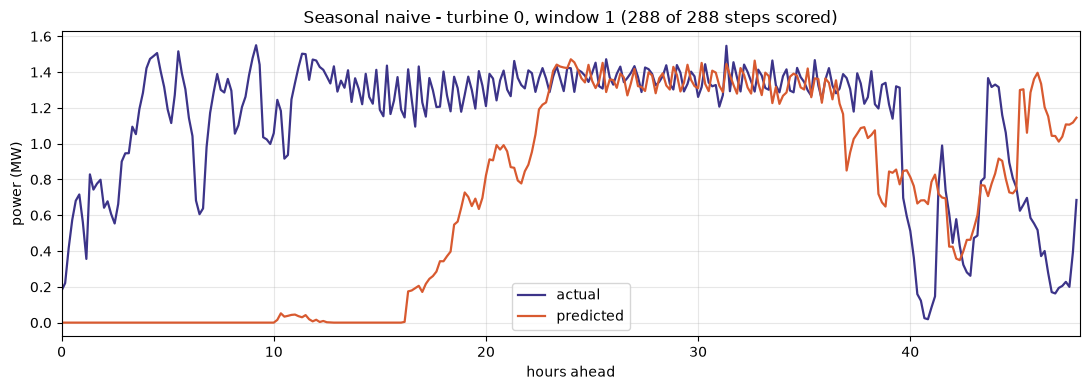

this turbine/window: RMSE 0.7748  MAE 0.5937  score 0.6842 MW  (288 of 288 steps scored, 0 masked)
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/pred_seasonal_naive.png


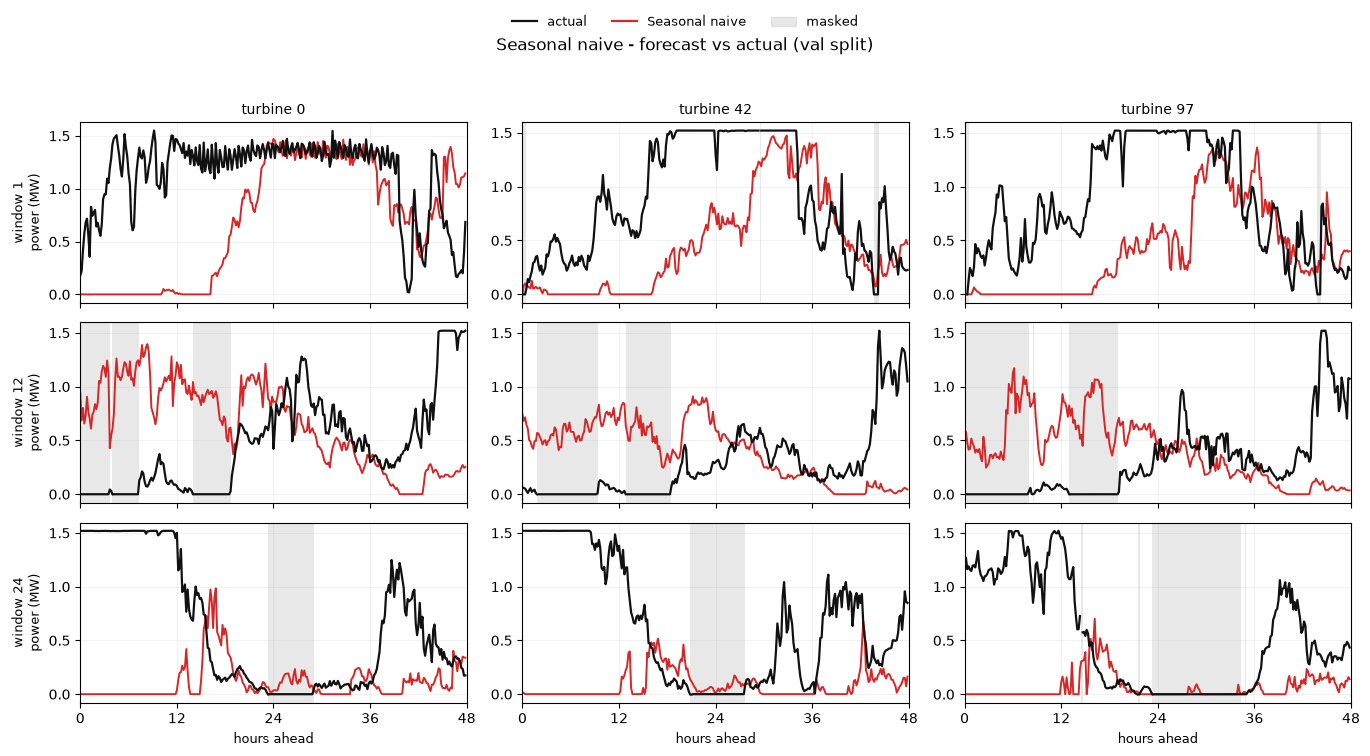

In [12]:
import baseline_naive; importlib.reload(baseline_naive)
print("LAG =", baseline_naive.LAG, "steps ({:.0f} h)".format(baseline_naive.LAG * 10 / 60))
MODULES["Seasonal naive"] = baseline_naive

show_prediction(baseline_naive, "Seasonal naive")
show_model_grid("Seasonal naive", baseline_naive)      # figure for the Seasonal Naive slide


In [13]:
RESULTS["Seasonal naive"] = report_score("Seasonal naive", score_model(baseline_naive))
# Analysis: naive repeats a fixed block of history. It tracks the daily shape but cannot
# react to anything new, so error grows with horizon and spikes wherever the copied block
# differs from the true future. Two effects are confounded in the LAG sweep -- diurnal
# alignment and evading the zero guard -- so LAG=432 beating LAG=288 is NOT evidence
# about wind persistence. What it does show about the farm: 53% of turbine-windows begin
# parked, so the score is dominated by how a model handles stopped turbines.


All predicted values are same as 0.0000 (12th prediction)!
Zero predicted values (12th prediction)! 
All predicted values are same as 0.0000 (16th prediction)!
Zero predicted values (16th prediction)! 
All predicted values are same as 0.0000 (17th prediction)!
Zero predicted values (17th prediction)! 
Seasonal naive         RMSE 66.321  MAE 52.527  score 59.424 MW  last-24h RMSE 64.083  (24 windows, 6s)


### 3.2 · Climatology

Averages power by **time of day** over the last `N_DAYS` of the window's own history and
tiles that typical day across 48 h. Uses no recent state, so it is the "what does this
turbine usually do at this hour" reference. No fitting, no artifact.

Module default `N_DAYS = 10` is the best point on the sweep.


N_DAYS = 10  AGG = mean  HALFLIFE_DAYS = None


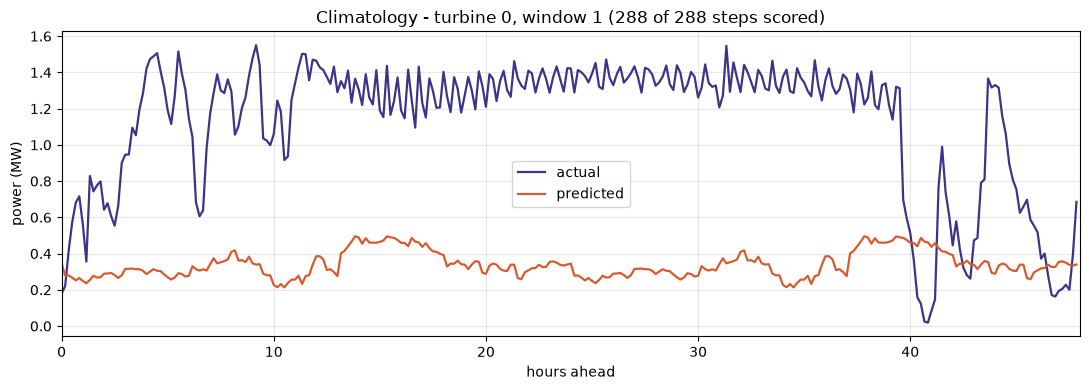

this turbine/window: RMSE 0.8798  MAE 0.8172  score 0.8485 MW  (288 of 288 steps scored, 0 masked)
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/pred_climatology.png


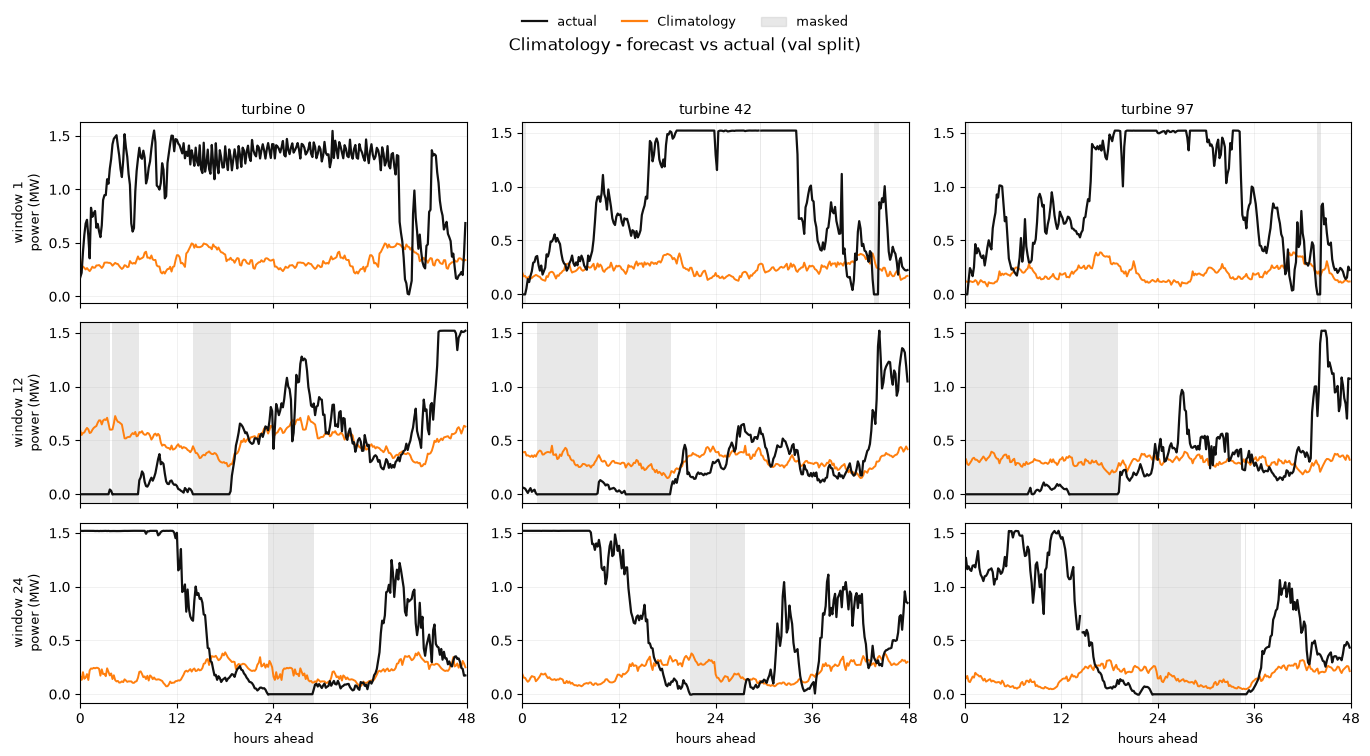

In [14]:
import baseline_climatology; importlib.reload(baseline_climatology)
print("N_DAYS =", baseline_climatology.N_DAYS, " AGG =", baseline_climatology.AGG,
      " HALFLIFE_DAYS =", baseline_climatology.HALFLIFE_DAYS)
MODULES["Climatology"] = baseline_climatology

show_prediction(baseline_climatology, "Climatology")
show_model_grid("Climatology", baseline_climatology)   # figure for the Climatology slide


In [15]:
RESULTS["Climatology"] = report_score("Climatology", score_model(baseline_climatology))
# Analysis: climatology ignores current conditions entirely -- the forecast is the average
# daily shape regardless of what the turbine is doing right now. The sweep found more
# history is better monotonically (2 -> 10 days), and the hard cutoff and the recency
# half-life trace the same path, so at a 48h horizon the recent weather regime carries no
# detectable extra information beyond the long-run daily shape. Both curves are still
# improving at the edge of the available history, so 10 days is a bound, not an optimum.


Climatology            RMSE 52.064  MAE 42.031  score 47.047 MW  last-24h RMSE 51.348  (24 windows, 6s)


### 3.3 · ARMA

One ARIMA(p, d, q) per turbine, fitted on that turbine's own power series — 134
independent models, fitted offline and loaded from a joblib artifact.

At prediction time the coefficients are held fixed while the Kalman filter is re-run over
`APPLY_STEPS` of recent history to establish the model's current **state** (fitting sets
the coefficients; the warm-up sets the state), then projected 288 steps ahead.

Artifact for this split comes from `SDWPF_ARIMA_MODEL`, set in the setup cell —
`arma_val.joblib` on validation, `arma_full.joblib` on test.


model path  : /home/dorsa/srip/windevolve_sdwpf/baselines/classical/arma_val.joblib [ok]
order       : (1, 0, 1)
fit_steps   : 4320 (30 days)
apply_steps : 144 (warm-up)


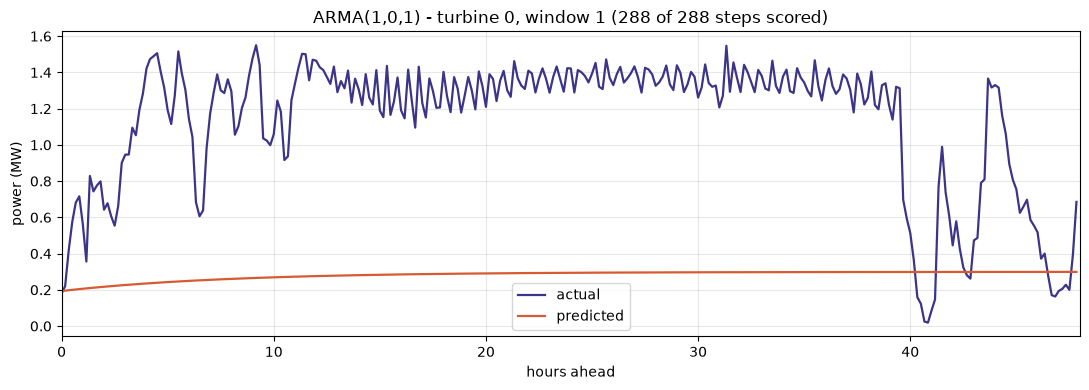

this turbine/window: RMSE 0.9260  MAE 0.8634  score 0.8947 MW  (288 of 288 steps scored, 0 masked)
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/pred_arma101.png


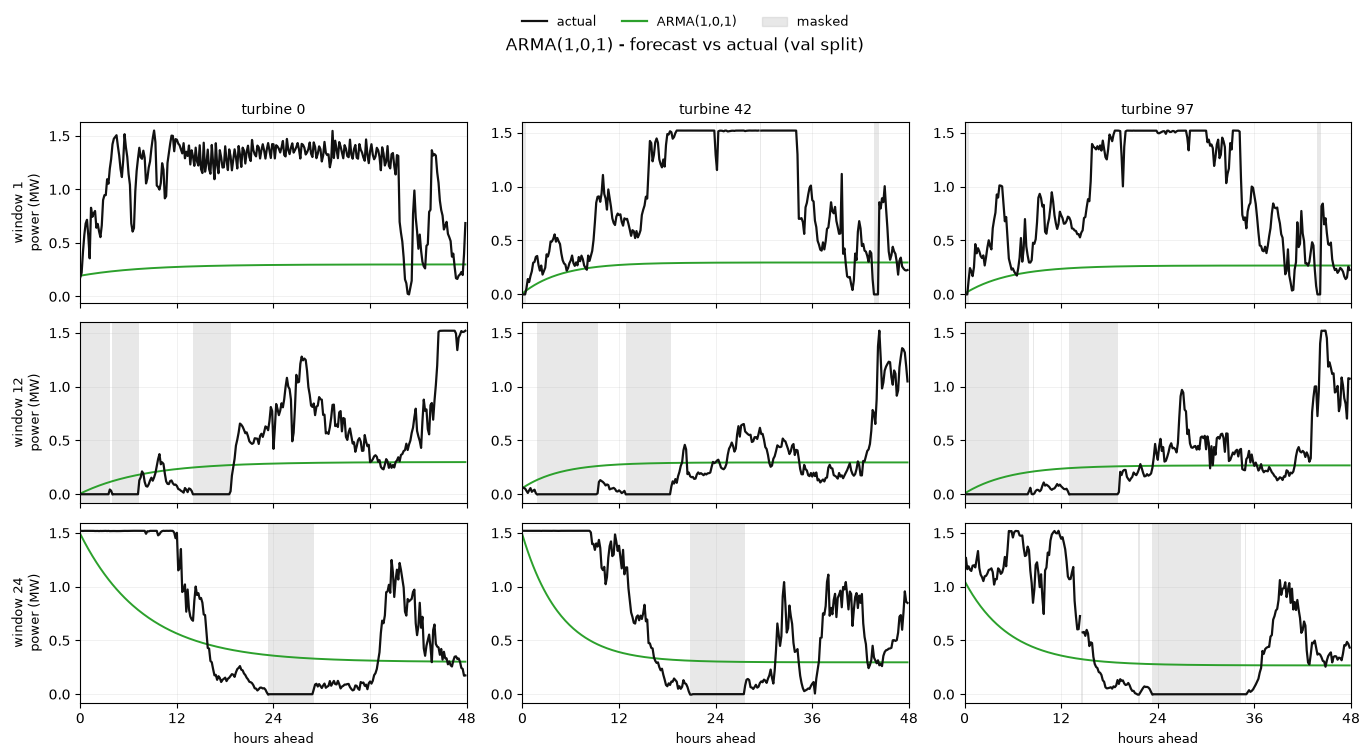

In [16]:
import baseline_arima; importlib.reload(baseline_arima)
baseline_arima._CACHE["fits"] = None        # clear the cache so the chosen artifact loads
print("model path  :", baseline_arima.MODEL_PATH,
      "[ok]" if os.path.exists(baseline_arima.MODEL_PATH) else "[MISSING]")
print("order       :", baseline_arima.DEFAULT_ORDER)
print("fit_steps   :", baseline_arima.FIT_STEPS,
      "({} days)".format(baseline_arima.FIT_STEPS // DAY_LEN))
print("apply_steps :", baseline_arima.APPLY_STEPS, "(warm-up)")
MODULES["ARMA(1,0,1)"] = baseline_arima

show_prediction(baseline_arima, "ARMA(1,0,1)")
show_model_grid("ARMA(1,0,1)", baseline_arima)         # figure for the ARMA slide


In [17]:
RESULTS["ARMA(1,0,1)"] = report_score("ARMA(1,0,1)", score_model(baseline_arima))
# Analysis: ARMA eases from the last value toward the series mean -- smooth, and well
# matched to the strong short-lag autocorrelation, which is why it is the best classical
# baseline on validation. Three sweep results to remember: model order barely matters
# ((2,0,2) improves by 0.09 MW, inside the noise floor); LESS training history wins
# (30 days beats 197), the opposite of what climatology wants from the same data; and
# warm-up length has no effect at all, because a stationary Kalman filter with fixed
# coefficients converges within a few dozen steps.


ARMA(1,0,1)            RMSE 48.705  MAE 39.943  score 44.324 MW  last-24h RMSE 50.401  (24 windows, 17s)


### 3.4 · XGBoost

A single global model shared by all 134 turbines. Direct multi-horizon regression: one
training row per (turbine, forecast origin, horizon step), with the horizon distance `h`
supplied as a feature, so the model is called once per step rather than fed its own
output — no compounding of error down the forecast.

Artifact from `SDWPF_GBDT_MODEL`: `gbdt_val.joblib` on validation, `gbdt_full.joblib` on
test. Module defaults are the tuned point: trees = 200, depth = 4, lr = 0.03, `base`
feature tier.


model path : /home/dorsa/srip/windevolve_sdwpf/baselines/tree/gbdt_val.joblib [ok]
features   : base (12 columns)
capacity   : trees=200 depth=4 lr=0.03


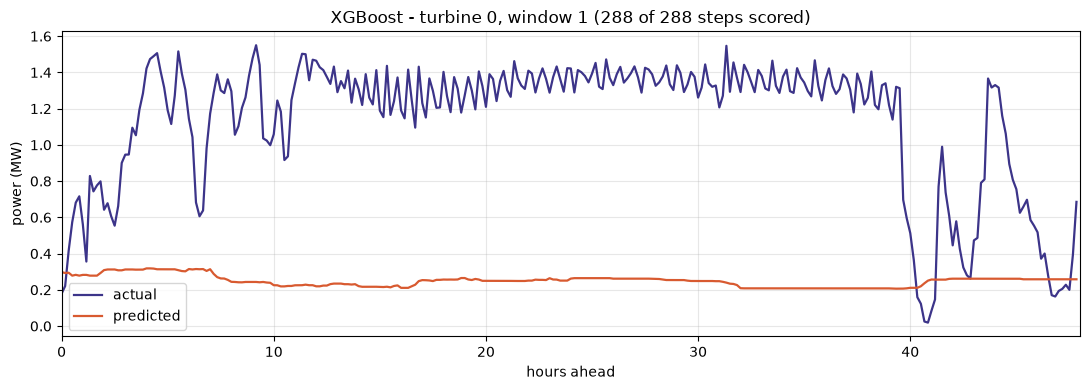

this turbine/window: RMSE 0.9604  MAE 0.8919  score 0.9262 MW  (288 of 288 steps scored, 0 masked)
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/pred_xgboost.png


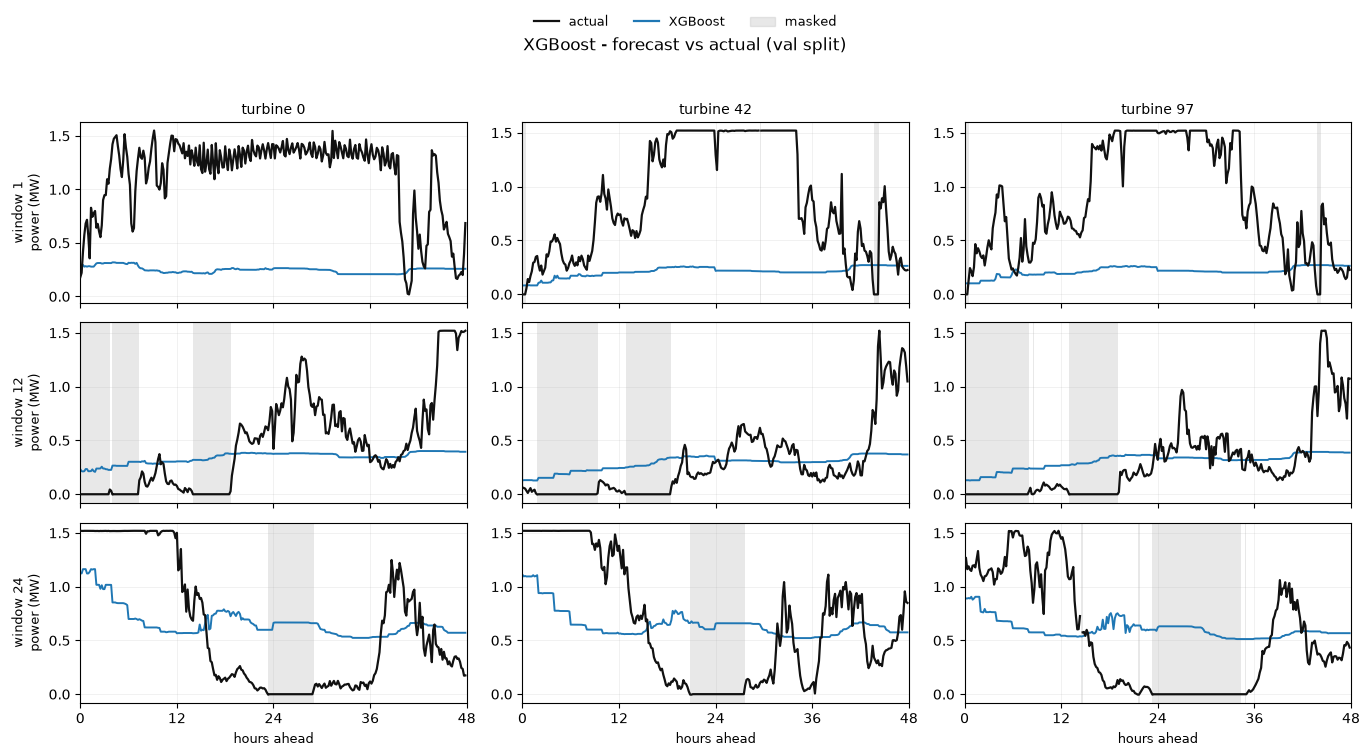

In [18]:
import baseline_gbdt; importlib.reload(baseline_gbdt)
baseline_gbdt._CACHE["model"] = None
print("model path :", baseline_gbdt.MODEL_PATH,
      "[ok]" if os.path.exists(baseline_gbdt.MODEL_PATH) else "[MISSING]")
print("features   :", baseline_gbdt.FEATURE_SET,
      "({} columns)".format(len(baseline_gbdt.feature_names(baseline_gbdt.FEATURE_SET))))
print("capacity   : trees={} depth={} lr={}".format(
    baseline_gbdt.N_ESTIMATORS, baseline_gbdt.MAX_DEPTH, baseline_gbdt.LEARNING_RATE))
MODULES["XGBoost"] = baseline_gbdt

show_prediction(baseline_gbdt, "XGBoost")
show_model_grid("XGBoost", baseline_gbdt)              # figure for the XGBoost slide


In [19]:
RESULTS["XGBoost"] = report_score("XGBoost", score_model(baseline_gbdt))
# Analysis: the only baseline that can read wind speed, but without FUTURE wind its
# power-curve advantage decays over 48h -- the sweep measured wind speed as worth nothing
# at this horizon. Note the piecewise-constant (blocky) prediction: trees predict in
# steps, which adds RMSE error on a smooth quantity. Every capacity axis says the model is
# overfitting, and adding nine auxiliary sensor channels costs 2.01 MW, the largest single
# effect in the whole study.


XGBoost                RMSE 49.307  MAE 41.093  score 45.200 MW  last-24h RMSE 51.021  (24 windows, 6s)


saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/gbdt_feature_importance.png


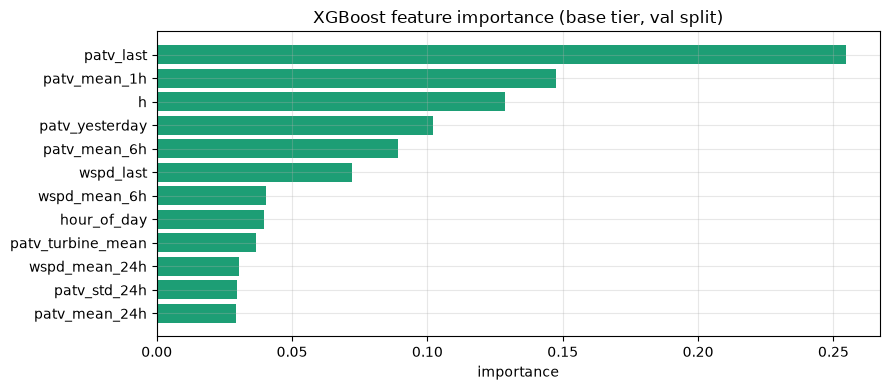

top features: patv_last (0.25), patv_mean_1h (0.15), h (0.13), patv_yesterday (0.10)


In [20]:
# XGBoost feature importances -- which inputs the tree model actually splits on.
blob = __import__("joblib").load(baseline_gbdt.MODEL_PATH)
model, feats = blob["model"], blob["features"]
imp = model.feature_importances_
order = np.argsort(imp)[::-1]
fig = plt.figure(figsize=(9, 4))
plt.barh([feats[i] for i in order][::-1], imp[order][::-1], color=TEAL)
plt.xlabel("importance")
plt.title("XGBoost feature importance ({} tier, {} split)".format(
    blob.get("feature_set", baseline_gbdt.FEATURE_SET), SPLIT))
plt.tight_layout(); savefig(fig, "gbdt_feature_importance"); plt.show()
print("top features:", ", ".join("{} ({:.2f})".format(feats[i], imp[i]) for i in order[:4]))
# Analysis: importance is not usefulness. The ablation is the real test -- features the
# model splits on happily (wind speed, neighbours, coordinates) all measured within noise
# or actively harmful when added. Read this chart as "what it leans on", then read the
# ablation for "what it gains".


### 3.5 · GRU

134 independent models, one per turbine: 24 h of history across 10 channels in, all 288
steps out, through a two-layer GRU with 48 hidden units. The official Baidu baseline
architecture, ported to PyTorch.

Checkpoints from `SDWPF_GRU_CHECKPOINTS`: `ckpt_val/` on validation, `ckpt_full/` on test.

One deliberate difference from the official `predict.py`: `INFER_DROPOUT` defaults to
`False`, so `model.eval()` **is** called and `forecast()` is deterministic. Set
`SDWPF_GRU_INFER_DROPOUT=1` to restore the official stochastic behaviour, in which case
one score is one draw and `score_model_draws()` applies.


checkpoints   : /home/dorsa/srip/windevolve_sdwpf/baselines/gru/ckpt_val
found         : 134 of 134
infer dropout : False (False = deterministic forecast)
full_run stamp: True
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/baselines/gru/ckpt_val


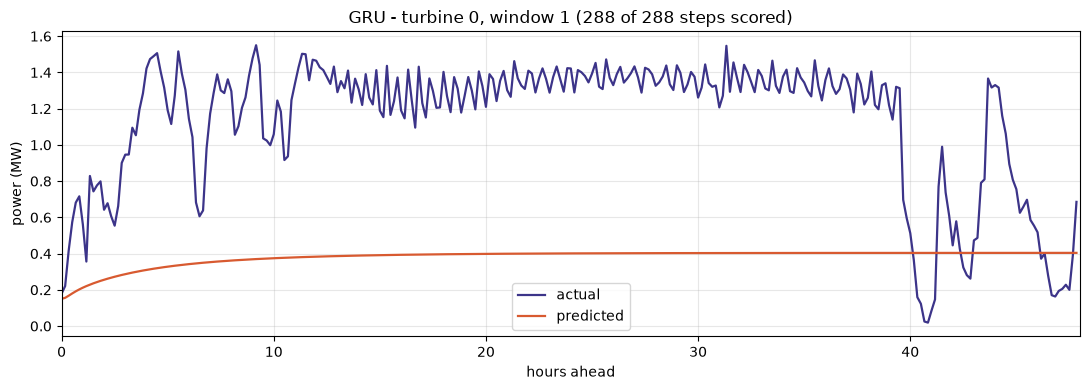

this turbine/window: RMSE 0.8337  MAE 0.7770  score 0.8053 MW  (288 of 288 steps scored, 0 masked)
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/pred_gru.png


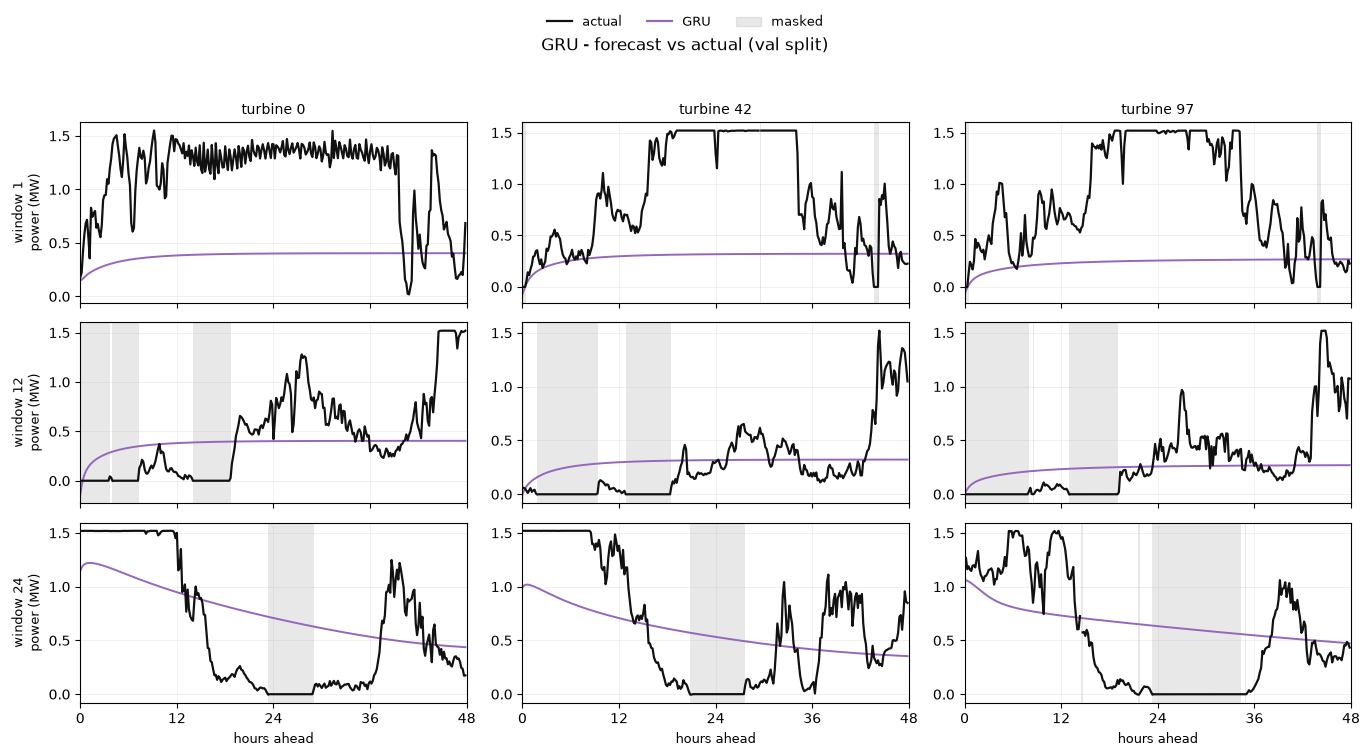

In [21]:
import gru_baseline; importlib.reload(gru_baseline)
gru_baseline._CACHE["models"] = None

GRU_CKPT = gru_baseline.CHECKPOINTS
have = sorted(int(os.path.basename(p).split("_")[1].split(".")[0])
              for p in glob.glob(os.path.join(GRU_CKPT, "model_*.pt")))
print("checkpoints   :", GRU_CKPT)
print("found         :", len(have), "of", CAPACITY)
print("infer dropout :", gru_baseline.INFER_DROPOUT, "(False = deterministic forecast)")

# Was this a single full-farm pass? Only such a run reproduces the official RNG stream.
if have:
    import torch
    _b = torch.load(os.path.join(GRU_CKPT, "model_{}.pt".format(have[0])),
                    map_location="cpu", weights_only=False)
    print("full_run stamp:", _b.get("full_run", "(pre-dates the stamp)"))
    if _b.get("full_run") is False:
        print("  !! partial run - reproduces neither the official stream nor a "
              "reportable baseline")

if len(have) >= CAPACITY:
    MODULES["GRU"] = gru_baseline
    show_prediction(gru_baseline, "GRU")
    show_model_grid("GRU", gru_baseline)               # figure for the GRU slide
elif have:
    print("Only {} of {} turbines - showing turbine {} in isolation "
          "(pipeline check, NOT comparable).".format(len(have), CAPACITY, have[0]))
    show_prediction(gru_baseline, "GRU (partial)", tid=have[0])
else:
    print("No checkpoints at that path. Check SDWPF_GRU_CHECKPOINTS in the setup cell.")


In [22]:
N_GRU_DRAWS = 5      # only meaningful with INFER_DROPOUT on; otherwise draws are identical

if "GRU" in MODULES:
    if gru_baseline.INFER_DROPOUT:
        RESULTS["GRU"] = report_score("GRU", score_model_draws(
            gru_baseline, n_draws=N_GRU_DRAWS, seed_env="SDWPF_GRU_INFER_SEED"))
        print("draws: " + ", ".join("{:.4f}".format(x)
                                    for x in RESULTS["GRU"].get("score_draws", [])))
    else:
        RESULTS["GRU"] = report_score("GRU", score_model(gru_baseline))
    r = RESULTS["GRU"]
    if r.get("valid") and SPLIT == "test":
        print("published official GRU: {:.3f} MW  (Scientific Data 11:649, Fig. 3)"
              .format(PUBLISHED_GRU))
        print("gap from published    : {:+.4f} MW".format(
            PUBLISHED_GRU - r["competition_score"]))
        print("for scale: the entire top-10 leaderboard span was 0.410 MW "
              "(HIK 44.917 to SlienceGTeam 45.327).")
    elif r.get("valid"):
        print("note: {:.3f} MW is on the {} split; the published 47.850 MW is on the "
              "142-window TEST set - not comparable.".format(r["competition_score"], SPLIT))
# Analysis: input length was the SMALLEST effect in the GRU sweep (144 -> 432 steps moves
# the score 0.043 MW) and the optimiser schedule the largest -- the default decays the
# learning rate to ~1/500 by epoch 10 and stops before the model converges.


GRU                    RMSE 48.499  MAE 40.576  score 44.537 MW  last-24h RMSE 50.772  (24 windows, 8s)
note: 44.537 MW is on the val split; the published 47.850 MW is on the 142-window TEST set - not comparable.


## 4 · Karpathy arm champion (run aug5b)

A four-line model, for comparison against the tuned baselines: exponential decay from a
one-step anchor toward a blend of the window's own 14-day climatology and the turbine's
long-run level, times a 0.85 shrink. Optional — skipped if the file is not there.


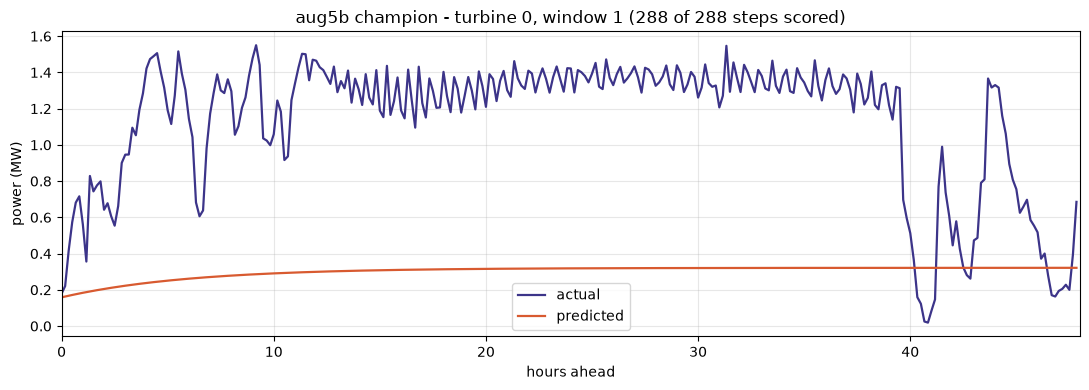

this turbine/window: RMSE 0.9070  MAE 0.8463  score 0.8767 MW  (288 of 288 steps scored, 0 masked)
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/pred_aug5b_champion.png


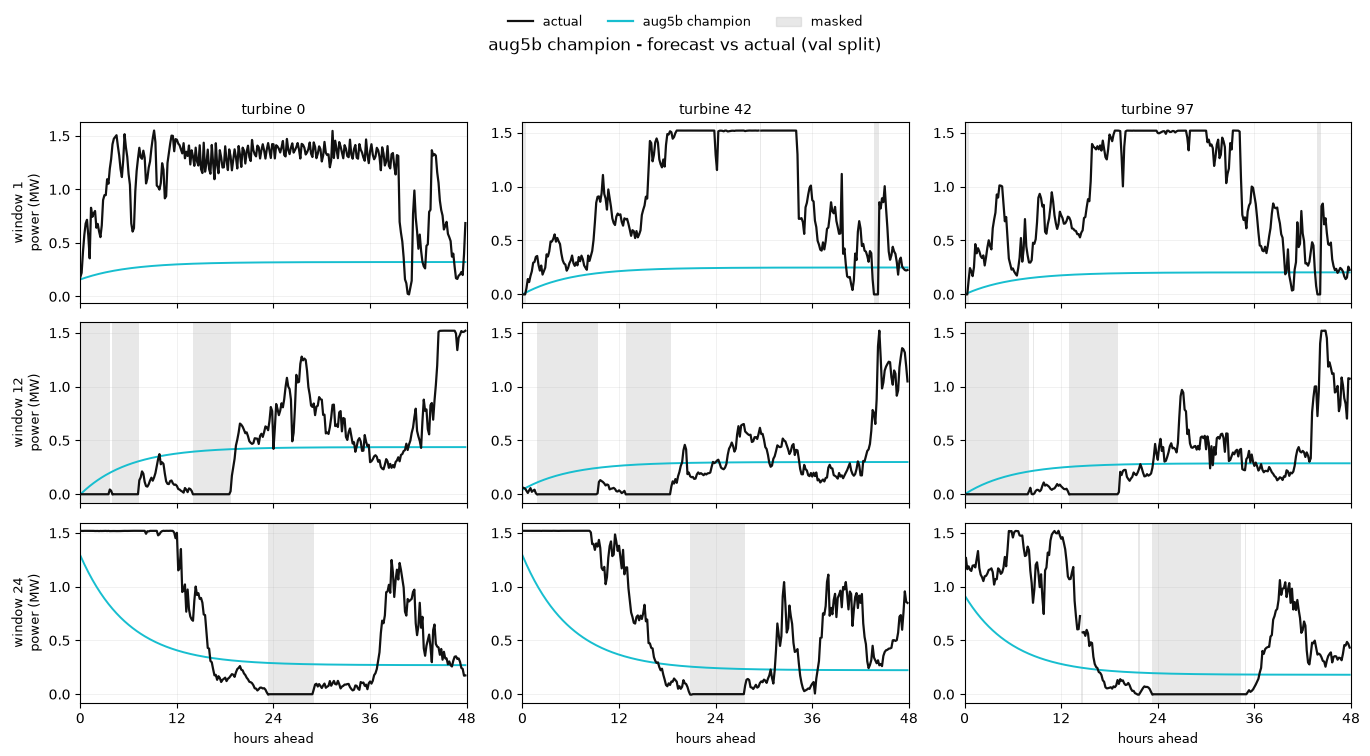

aug5b champion         RMSE 48.255  MAE 39.281  score 43.768 MW  last-24h RMSE 49.727  (24 windows, 6s)


In [23]:
CHAMPION = os.path.join(P.RUNS_DIR, "karpathy__aug5b", "forecaster.py")

if os.path.exists(CHAMPION):
    spec = importlib.util.spec_from_file_location("aug5b_champion", CHAMPION)
    champion = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(champion)
    MODULES["aug5b champion"] = champion
    show_prediction(champion, "aug5b champion")
    show_model_grid("aug5b champion", champion)
    RESULTS["aug5b champion"] = report_score("aug5b champion", score_model(champion))
else:
    print("no champion at", CHAMPION, "- skipping")
# Analysis: it beats every tuned baseline on validation with no training and ~6s per
# evaluation, but by 0.556 MW over ARMA -- only about 1.4x the measured noise floor of
# 0.396 MW. Its ordering does not survive the test set: 1st here, 3rd there.


## 5 · All models on one plot

One panel per (window, turbine), every model overlaid on the truth. Black is the truth;
grey spans are steps the official mask excludes, where a model can look wrong at no cost
to its score. A single panel can always be cherry-picked; a grid cannot.


overlaying: Seasonal naive, Climatology, ARMA(1,0,1), XGBoost, GRU, aug5b champion
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/all_models_grid.png


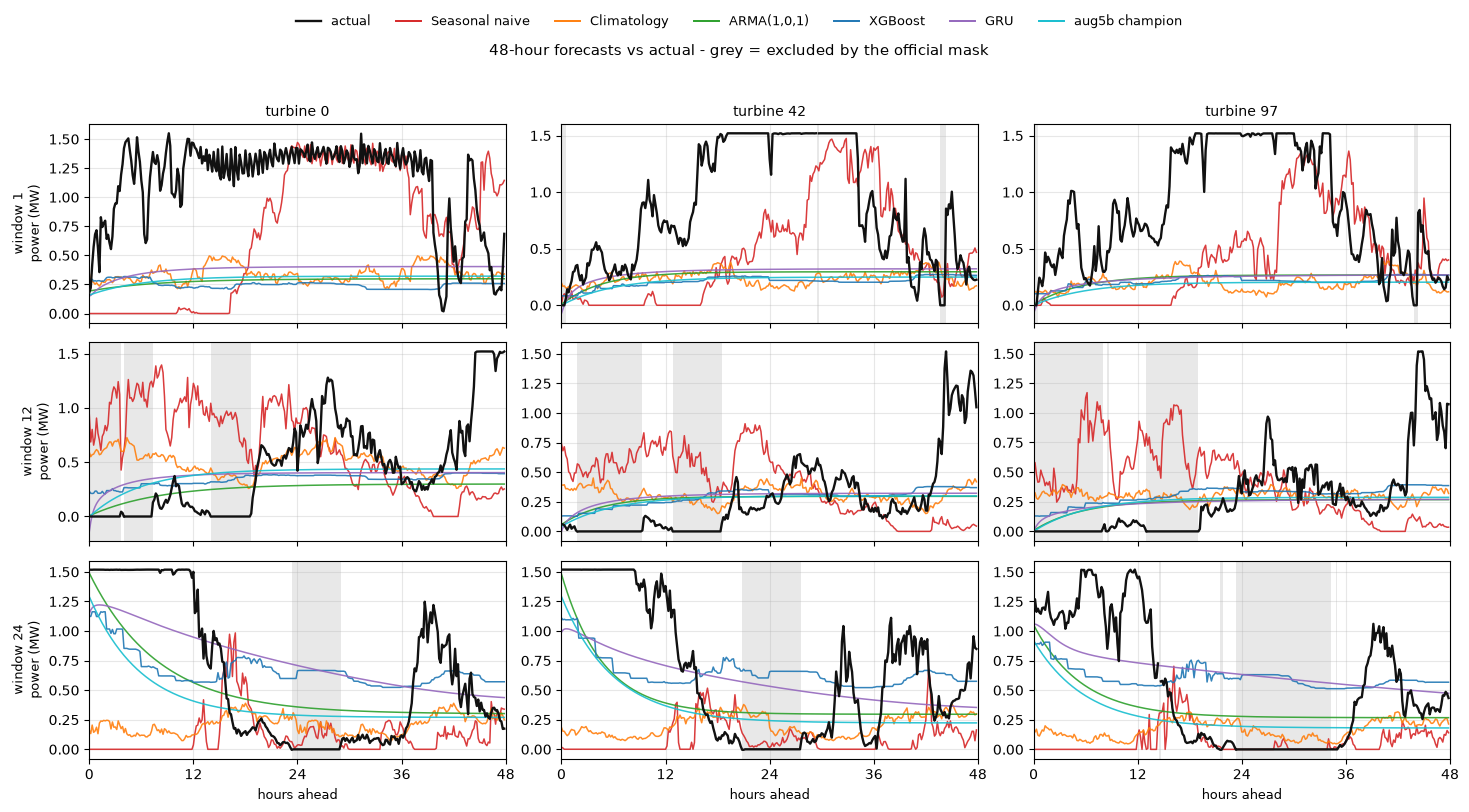

In [24]:
NAMES = [n for n in COLOURS if n in MODULES]      # fixed order, fixed colours
print("overlaying:", ", ".join(NAMES))


def panel(ax, widx, tid, names=None):
    names = names or NAMES
    truth, keep = truth_window(widx)
    shade_mask(ax, keep[tid])
    ax.plot(HOURS, truth[tid] / 1000, color=COLOURS["actual"], lw=1.7,
            label="actual", zorder=6)
    for n in names:
        ax.plot(HOURS, predict_window(n, MODULES[n], widx)[tid] / 1000,
                color=COLOURS.get(n), lw=1.1, alpha=0.9, label=n)
    ax.set_xlim(0, 48); ax.set_xticks([0, 12, 24, 36, 48])


nrow, ncol = len(WINDOWS), len(TURBINES)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.9 * ncol, 2.7 * nrow),
                         squeeze=False, sharex=True)
for r, w in enumerate(WINDOWS):
    for c, t in enumerate(TURBINES):
        panel(axes[r][c], w, t)
        if r == 0:
            axes[r][c].set_title("turbine {}".format(t), fontsize=10)
        if c == 0:
            axes[r][c].set_ylabel("window {}\npower (MW)".format(w + 1), fontsize=9)
        if r == nrow - 1:
            axes[r][c].set_xlabel("hours ahead", fontsize=9)
handles = [plt.Line2D([], [], color=COLOURS["actual"], lw=1.7, label="actual")]
handles += [plt.Line2D([], [], color=COLOURS[n], lw=1.4, label=n) for n in NAMES]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), fontsize=9,
           frameon=False, bbox_to_anchor=(0.5, 1.005))
fig.suptitle("48-hour forecasts vs actual - grey = excluded by the official mask",
             y=0.955, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.935))
savefig(fig, "all_models_grid"); plt.show()


saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/all_models_single.png


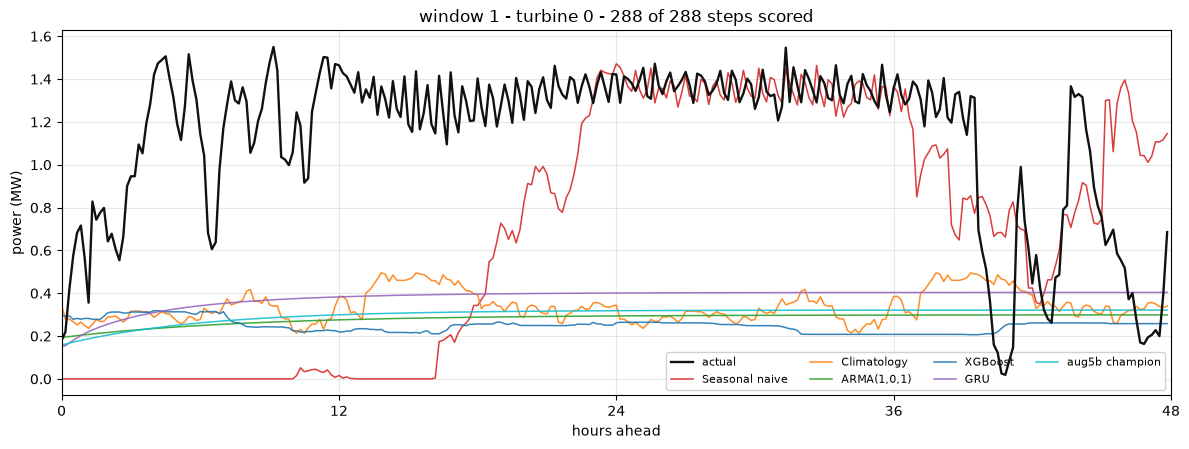

,model,RMSE_MW,MAE_MW,score_MW,bias_kW
0,Seasonal naive,0.7748,0.5937,0.6842,-446.7
1,GRU,0.8337,0.7770,0.8053,-751.4
2,Climatology,0.8798,0.8172,0.8485,-791.9
3,aug5b champion,0.9070,0.8463,0.8767,-830.5
4,"ARMA(1,0,1)",0.9260,0.8634,0.8947,-849.8
5,XGBoost,0.9604,0.8919,0.9262,-881.8


In [25]:
# One panel, full width, with the legend - for reading a single case closely.
W, T = WINDOWS[0], TURBINES[0]
fig, ax = plt.subplots(figsize=(12, 4.6))
panel(ax, W, T)
truth, keep = truth_window(W)
ax.set_xlabel("hours ahead"); ax.set_ylabel("power (MW)")
ax.set_title("window {} - turbine {} - {} of {} steps scored".format(
    W + 1, T, int(keep[T].sum()), HORIZON))
ax.legend(ncol=4, fontsize=8, framealpha=0.9)
plt.tight_layout(); savefig(fig, "all_models_single"); plt.show()

# Per-turbine-window scores on the scored steps only. This is ONE of the 134
# contributions the metric SUMS for this window, not a farm score.
rows = []
for n in NAMES:
    p = predict_window(n, MODULES[n], W)[T][keep[T]]
    g = truth[T][keep[T]]
    if p.size:
        e = (p - g) / 1000.0
        rmse, mae = float(np.sqrt((e ** 2).mean())), float(np.abs(e).mean())
        rows.append({"model": n, "RMSE_MW": round(rmse, 4), "MAE_MW": round(mae, 4),
                     "score_MW": round(0.5 * (rmse + mae), 4),
                     "bias_kW": round(float((p - g).mean()), 1)})
pd.DataFrame(rows).sort_values("score_MW").reset_index(drop=True)


## 6 · Farm aggregate, and where the error lives

Single turbines are illustrative; the metric **sums** over all 134, so the farm total is
closer to what the score is actually built from. The horizon curve is the one that
explains the regime table: persistence-like models win the first few hours,
climatology-like models win past ~12 h, and the crossover is where a switching program
has something to gain.


saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/farm_aggregate.png


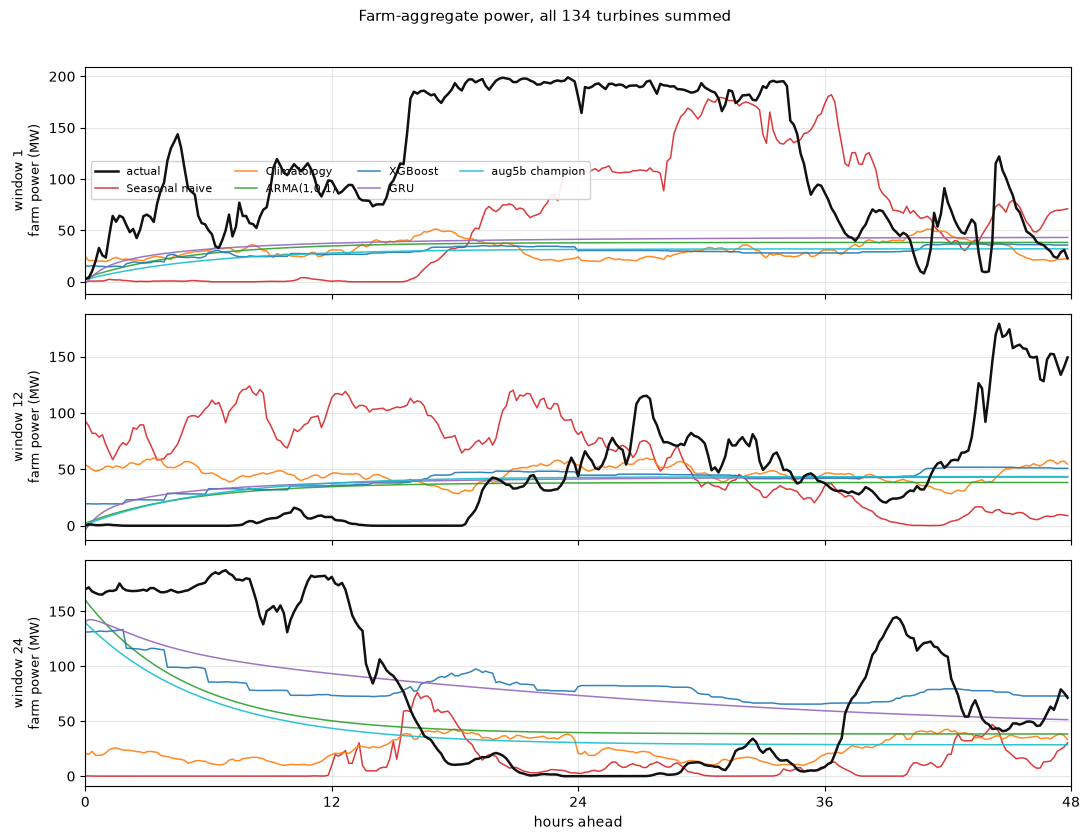

In [26]:
fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(11, 2.8 * len(WINDOWS)),
                         squeeze=False, sharex=True)
for r, w in enumerate(WINDOWS):
    ax = axes[r][0]
    truth, _ = truth_window(w)
    ax.plot(HOURS, np.nansum(truth, axis=0) / 1000.0, color=COLOURS["actual"],
            lw=1.8, label="actual", zorder=6)
    for n in NAMES:
        ax.plot(HOURS, predict_window(n, MODULES[n], w).sum(axis=0) / 1000.0,
                color=COLOURS[n], lw=1.1, alpha=0.9, label=n)
    ax.set_ylabel("window {}\nfarm power (MW)".format(w + 1), fontsize=9)
    ax.set_xlim(0, 48); ax.set_xticks([0, 12, 24, 36, 48])
    if r == 0:
        ax.legend(ncol=4, fontsize=8, framealpha=0.9)
axes[-1][0].set_xlabel("hours ahead")
fig.suptitle("Farm-aggregate power, all 134 turbines summed", y=0.995, fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.98))
savefig(fig, "farm_aggregate"); plt.show()


saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/error_vs_horizon.png


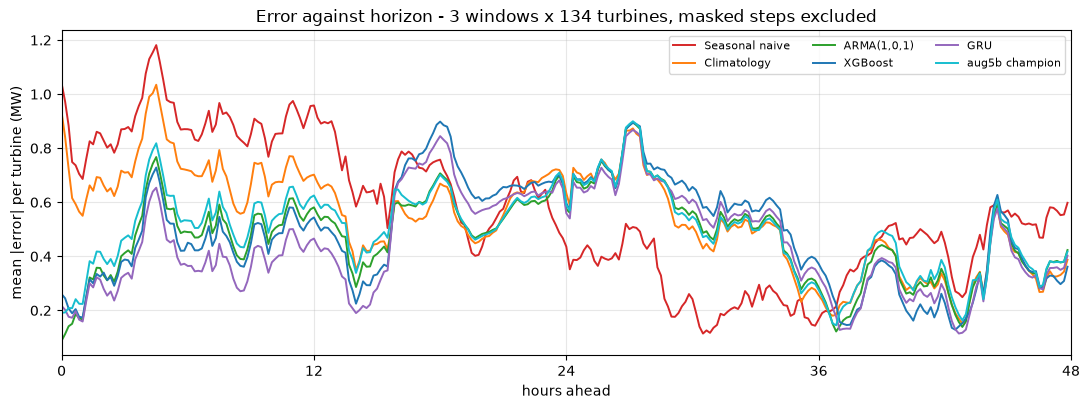

mean |error| per turbine (MW) by horizon bucket - lowest per column wins


,0-6h,6-12h,12-24h,24-36h,36-48h
model,,,,,
Seasonal naive,0.900,0.883,0.651,0.275,0.443
Climatology,0.747,0.689,0.565,0.547,0.327
"ARMA(1,0,1)",0.417,0.512,0.540,0.569,0.322
XGBoost,0.400,0.476,0.607,0.623,0.295
GRU,0.355,0.392,0.557,0.584,0.296
aug5b champion,0.473,0.555,0.559,0.562,0.346


In [27]:
# Mean |error| against horizon, over every turbine in the plotted windows, masked out.
err = {n: np.zeros(HORIZON) for n in NAMES}
cnt = np.zeros(HORIZON)
for w in WINDOWS:
    truth, keep = truth_window(w)
    cnt += keep.sum(axis=0)
    for n in NAMES:
        d = np.abs(predict_window(n, MODULES[n], w) - truth) / 1000.0
        err[n] += np.where(keep, d, 0.0).sum(axis=0)
cnt = np.maximum(cnt, 1)

fig = plt.figure(figsize=(11, 4.2))
for n in NAMES:
    plt.plot(HOURS, err[n] / cnt, color=COLOURS[n], lw=1.4, label=n)
plt.xlabel("hours ahead"); plt.ylabel("mean |error| per turbine (MW)")
plt.title("Error against horizon - {} windows x {} turbines, masked steps excluded".format(
    len(WINDOWS), CAPACITY))
plt.xlim(0, 48); plt.xticks([0, 12, 24, 36, 48]); plt.legend(ncol=3, fontsize=8)
plt.tight_layout(); savefig(fig, "error_vs_horizon"); plt.show()

buckets = [(0, 6), (6, 12), (12, 24), (24, 36), (36, 48)]
rows = []
for n in NAMES:
    row = {"model": n}
    for a, b in buckets:
        sl = slice(a * 6, b * 6)
        row["{}-{}h".format(a, b)] = round(float(err[n][sl].sum() / cnt[sl].sum()), 3)
    rows.append(row)
print("mean |error| per turbine (MW) by horizon bucket - lowest per column wins")
pd.DataFrame(rows).set_index("model")


## 7 · Guards

Three checks the official grader applies **before** it will emit a score. Each one
rejects the whole window, so a model can be excellent and still return nothing.

| guard | per-turbine flag | window rejected when |
|---|---|---|
| zero prediction | the whole 288-step forecast is zero (`np.any()`, so one non-zero value clears it) | non-zero turbine ratio < 0.9 |
| identical prediction | forecast is constant, or `std <= 0.1` with fewer than 10% distinct values | varying turbine ratio < 0.1 |
| accuracy | — | `acc = 1 - (sum_i RMSE_i over the last 24 h) / capacity <= 0` |

`capacity` is the **turbine count** and the RMSEs are summed, so the division is an
average and the accuracy gate reduces to: *mean per-turbine last-24 h RMSE ≥ 1 MW →
rejected.*

The functions below call `official_metrics` directly, so these are the grader's own
numbers rather than a re-implementation.


saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/guard_margins.png


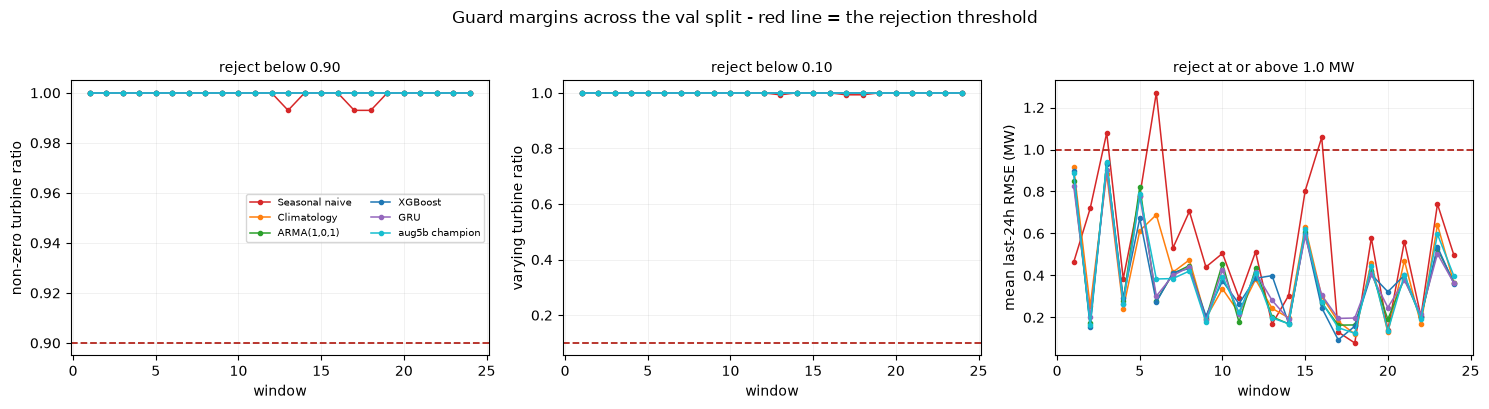

closest approach to each threshold, over all windows:


,min non_zero_ratio,min varying_ratio,max last24h_RMSE_MW
model,,,
Seasonal naive,0.993,0.993,1.270
Climatology,1.000,1.000,0.915
"ARMA(1,0,1)",1.000,1.000,0.935
XGBoost,1.000,1.000,0.933
GRU,1.000,1.000,0.904
aug5b champion,1.000,1.000,0.940


In [28]:
def guard_margins(name, module, windows=None):
    # Per window: non-zero ratio, varying ratio, and mean last-24h RMSE.
    windows = range(len(infiles)) if windows is None else windows
    rows = []
    for w in windows:
        pred = predict_window(name, module, w)                    # (134, 288) kW
        zero_flags, var_flags = [], []
        for t in range(CAPACITY):
            p = pred[t].reshape(-1, 1)
            zero_flags.append(OM.check_zero_prediction(p))
            var_flags.append(OM.check_identical_prediction(
                p, min_distinct_ratio=EV.MIN_DISTINCT_RATIO))
        non_zero = float(np.mean(np.array(zero_flags) == 0))
        varying = float(np.mean(np.array(var_flags) == 0))

        truth, keep = truth_window(w)
        last = slice(HORIZON - DAY_LEN, HORIZON)                  # final 24 h
        per_turb = []
        for t in range(CAPACITY):
            m = keep[t][last]
            if m.sum():
                e = (pred[t][last][m] - truth[t][last][m]) / 1000.0
                per_turb.append(float(np.sqrt((e ** 2).mean())))
        rows.append({"window": w + 1, "non_zero_ratio": round(non_zero, 3),
                     "varying_ratio": round(varying, 3),
                     "last24h_RMSE_MW": round(float(np.mean(per_turb)), 3) if per_turb else np.nan})
    return pd.DataFrame(rows)


with contextlib.redirect_stdout(io.StringIO()):     # the grader prints per turbine
    margins = {n: guard_margins(n, MODULES[n]) for n in NAMES}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [("non_zero_ratio", 0.9, "non-zero turbine ratio", "reject below 0.90"),
          ("varying_ratio", 0.1, "varying turbine ratio", "reject below 0.10"),
          ("last24h_RMSE_MW", 1.0, "mean last-24h RMSE (MW)", "reject at or above 1.0 MW")]
for ax, (col, thr, label, note) in zip(axes, panels):
    for n in NAMES:
        ax.plot(margins[n]["window"], margins[n][col], marker="o", ms=3, lw=1.1,
                color=COLOURS.get(n), label=n)
    ax.axhline(thr, color="#B3261E", ls="--", lw=1.3)
    ax.set_xlabel("window"); ax.set_ylabel(label)
    ax.set_title(note, fontsize=10); ax.grid(alpha=0.25, lw=0.5)
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle("Guard margins across the {} split - red line = the rejection threshold".format(SPLIT),
             y=1.01, fontsize=12)
fig.tight_layout(); savefig(fig, "guard_margins"); plt.show()

print("closest approach to each threshold, over all windows:")
pd.DataFrame([{"model": n,
               "min non_zero_ratio": margins[n]["non_zero_ratio"].min(),
               "min varying_ratio": margins[n]["varying_ratio"].min(),
               "max last24h_RMSE_MW": margins[n]["last24h_RMSE_MW"].max()}
              for n in NAMES]).set_index("model")


LAG for this cell only: 144
window 1: 0.0% of turbines have an ALL-ZERO forecast -> non-zero ratio 1.000
threshold is 0.90, so this window is accepted
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/guard_zero_prediction_tripped.png


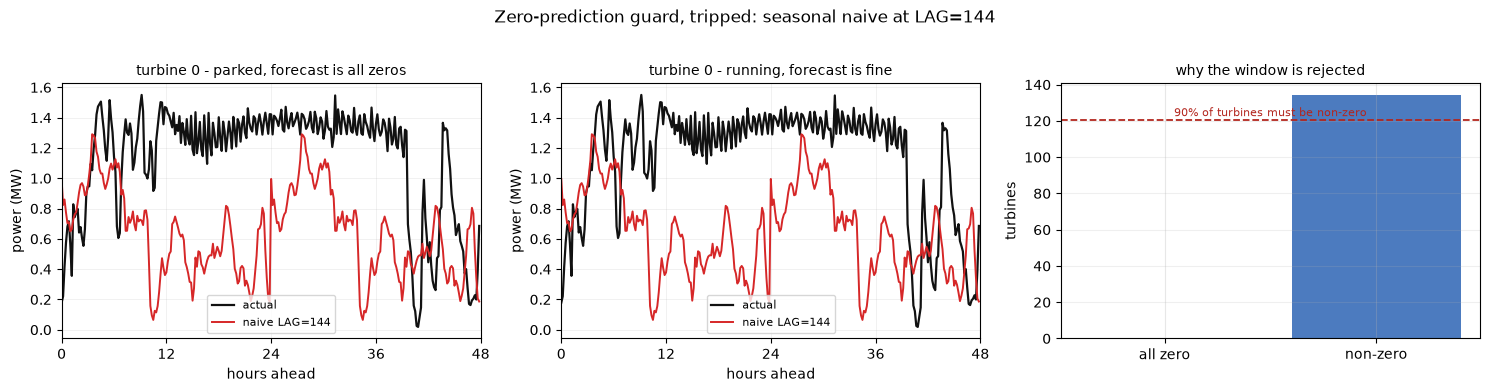

restored LAG = 432


In [29]:
# A configuration that DOES trip a guard: seasonal naive at LAG=144. Copying the previous
# 24 h forward gives an all-zero forecast for every turbine parked during that day.
os.environ["SDWPF_NAIVE_LAG"] = "144"
import baseline_naive as _bn144; importlib.reload(_bn144)
print("LAG for this cell only:", _bn144.LAG)

TRIP_W = WINDOWS[0]
pred144 = np.asarray(_bn144.forecast(prep_env(infiles[TRIP_W])),
                     dtype=float).reshape(CAPACITY, HORIZON)
all_zero = np.array([not np.any(pred144[t]) for t in range(CAPACITY)])
non_zero_ratio = 1 - all_zero.mean()
print("window {}: {:.1f}% of turbines have an ALL-ZERO forecast -> non-zero ratio {:.3f}"
      .format(TRIP_W + 1, 100 * all_zero.mean(), non_zero_ratio))
print("threshold is 0.90, so this window is {}".format(
    "REJECTED" if non_zero_ratio < EV.MIN_NON_ZERO_RATIO else "accepted"))

truth, keep = truth_window(TRIP_W)
dead = int(np.argmax(all_zero)) if all_zero.any() else 0
alive = int(np.argmax(~all_zero))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, t, lab in [(axes[0], dead, "turbine {} - parked, forecast is all zeros".format(dead)),
                   (axes[1], alive, "turbine {} - running, forecast is fine".format(alive))]:
    shade_mask(ax, keep[t])
    ax.plot(HOURS, truth[t] / 1000, color=COLOURS["actual"], lw=1.6, label="actual")
    ax.plot(HOURS, pred144[t] / 1000, color="#d62728", lw=1.4, label="naive LAG=144")
    ax.set_xlim(0, 48); ax.set_xticks([0, 12, 24, 36, 48])
    ax.set_xlabel("hours ahead"); ax.set_ylabel("power (MW)")
    ax.set_title(lab, fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.25, lw=0.5)

axes[2].bar(["all zero", "non-zero"], [all_zero.sum(), (~all_zero).sum()],
            color=["#d62728", "#4C7BBF"])
axes[2].axhline(EV.MIN_NON_ZERO_RATIO * CAPACITY, color="#B3261E", ls="--", lw=1.3)
axes[2].text(0.5, EV.MIN_NON_ZERO_RATIO * CAPACITY + 2,
             "90% of turbines must be non-zero", fontsize=8, color="#B3261E", ha="center")
axes[2].set_ylabel("turbines"); axes[2].set_title("why the window is rejected", fontsize=10)
axes[2].grid(alpha=0.2, axis="y")
fig.suptitle("Zero-prediction guard, tripped: seasonal naive at LAG=144", y=1.02, fontsize=12)
fig.tight_layout(); savefig(fig, "guard_zero_prediction_tripped"); plt.show()

os.environ.pop("SDWPF_NAIVE_LAG", None)     # back to the module default (432)
importlib.reload(baseline_naive)
print("restored LAG =", baseline_naive.LAG)
# Analysis: the guard is not punishing a bad forecast -- for the parked turbine the
# all-zero forecast is CORRECT. It is punishing a degenerate one, and it cannot tell the
# difference. Worth knowing before an evolved program is credited for a sudden
# improvement: check its output is not flat before believing it.


## 8 · Summary

Every model above, on the same windows and the same metric. The grey band is the measured
noise floor above the leader — anything inside it is a tie, not a win.


BASELINE COMPARISON  (MW, summed over 134 turbines, averaged over windows; lower better)
split : val   artifacts: _val   metric: official Baidu KDD Cup 2022 grader, verbatim

         model  MAE_MW  RMSE_MW  score_MW  std  windows  eval_s  comparable
aug5b champion   39.28    48.25    43.768  0.0       24     5.6        True
   ARMA(1,0,1)   39.94    48.70    44.324  0.0       24    17.3        True
           GRU   40.58    48.50    44.537  0.0       24     7.9        True
       XGBoost   41.09    49.31    45.200  0.0       24     6.2        True
   Climatology   42.03    52.06    47.047  0.0       24     5.9        True
Seasonal naive   52.53    66.32    59.424  0.0       24     5.8        True
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/summary_bars.png


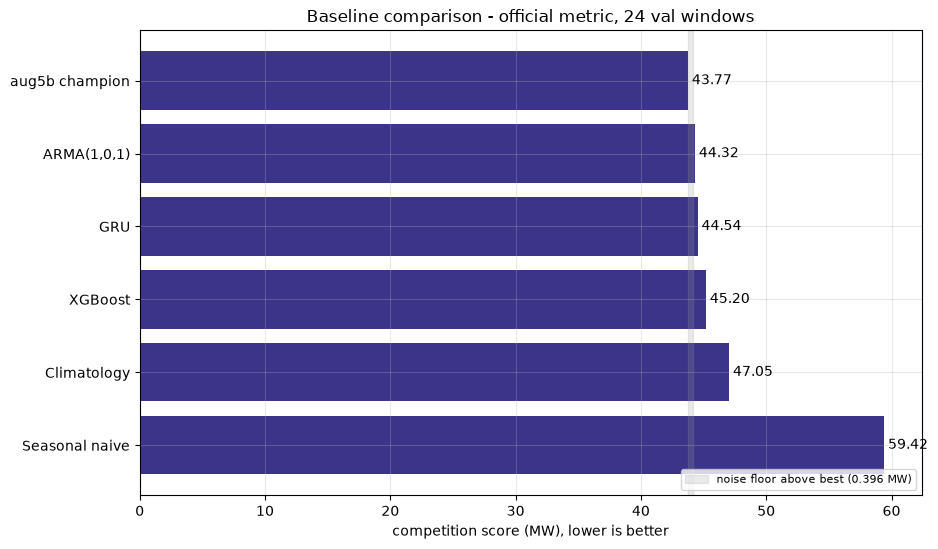

In [30]:
NOISE_FLOOR = 0.396      # MW, 1 sd - measured on XGBoost seeds 42/43/44

rows = []
for name, res in RESULTS.items():
    if not res.get("valid"):
        continue
    rows.append({"model": name,
                 "MAE_MW": round(res["mae"], 2),
                 "RMSE_MW": round(res["rmse"], 2),
                 "score_MW": round(res["competition_score"], 3),
                 "std": round(res.get("score_std", 0.0), 3),
                 "windows": res["n_windows"],
                 "eval_s": round(res.get("eval_seconds", 0), 1),
                 "comparable": res.get("comparable", False)})
tbl = pd.DataFrame(rows).sort_values("score_MW").reset_index(drop=True)
print("BASELINE COMPARISON  (MW, summed over 134 turbines, averaged over windows; lower better)")
print("split : {}   artifacts: {}   metric: official Baidu KDD Cup 2022 grader, verbatim\n"
      .format(SPLIT, "_val" if SPLIT == "val" else "_full"))
print(tbl.to_string(index=False))

failed = [(n, r.get("reason", "")) for n, r in RESULTS.items() if not r.get("valid")]
if failed:
    print("\nnot scored:")
    for n, why in failed:
        print("  {:<22} {}".format(n, why))
if len(tbl) and not tbl["comparable"].all():
    print("\nNOTE: rows with comparable=False hit a run-level gate, or were scored on "
          "fewer than\n      the official 142 windows. NOT comparable with published numbers.")

if len(tbl):
    best = tbl["score_MW"].min()
    fig, ax = plt.subplots(figsize=(9.5, 0.7 * len(tbl) + 1.4))
    y = np.arange(len(tbl))
    ax.barh(y, tbl["score_MW"], color=NAVY)
    if (tbl["std"] > 0).any():
        ax.errorbar(tbl["score_MW"], y, xerr=tbl["std"], fmt="none",
                    ecolor=GOLD, elinewidth=2, capsize=4)
    ax.set_yticks(y); ax.set_yticklabels(tbl["model"]); ax.invert_yaxis()
    ax.set_xlabel("competition score (MW), lower is better")
    for i, v in enumerate(tbl["score_MW"]):
        ax.text(v + 0.3, i, "{:.2f}".format(v), va="center")
    ax.axvspan(best, best + NOISE_FLOOR, color="#999999", alpha=0.20,
               label="noise floor above best ({:.3f} MW)".format(NOISE_FLOOR))
    if SPLIT == "test":
        ax.axvline(PUBLISHED_GRU, color=RUST, ls="--", lw=1.3)
        ax.text(PUBLISHED_GRU, -0.75, " published GRU {:.2f}".format(PUBLISHED_GRU),
                color=RUST, fontsize=8, va="bottom")
        ax.axvline(PUBLISHED_BEST_TEAM, color=TEAL, ls=":", lw=1.3)
        ax.text(PUBLISHED_BEST_TEAM, -0.75, " best team {:.2f} ".format(PUBLISHED_BEST_TEAM),
                color=TEAL, fontsize=8, va="bottom", ha="right")
    ax.legend(fontsize=8, loc="lower right")
    ax.set_title("Baseline comparison - official metric, {} {} windows".format(
        int(tbl["windows"].max()), SPLIT))
    plt.tight_layout(); savefig(fig, "summary_bars"); plt.show()


## 9 · Validation → test

The question here is not "how good is the model" but **does the ordering transfer**.
Selecting on validation is correct; what needs checking is whether that selection means
anything on data the selection never saw.

Each row pairs a `_val` artifact scored on the 24 validation windows with the matching
`_full` artifact scored on the 142 test windows. Fill `KNOWN` from measurements already
made so this section runs without re-reading the locked test set.


         model    val_MW  test_MW  gap_MW  val_rank  test_rank
aug5b champion 43.767716   47.608   3.840         1          3
   ARMA(1,0,1) 44.323891   49.605   5.281         2          4
           GRU 44.537366   46.809   2.272         3          2
       XGBoost 45.200184   46.804   1.604         4          1
   Climatology 47.047406   50.487   3.440         5          5

Spearman rho (validation rank vs test rank), n = 5: +0.10
At n = 5, |rho| would need to be about 0.9 to be distinguishable from chance, so
read this as 'no evidence the ordering transfers', not 'the ordering inverts'.
saved: /home/dorsa/srip/windevolve_sdwpf/runs/plots/notebook/val/val_vs_test.png


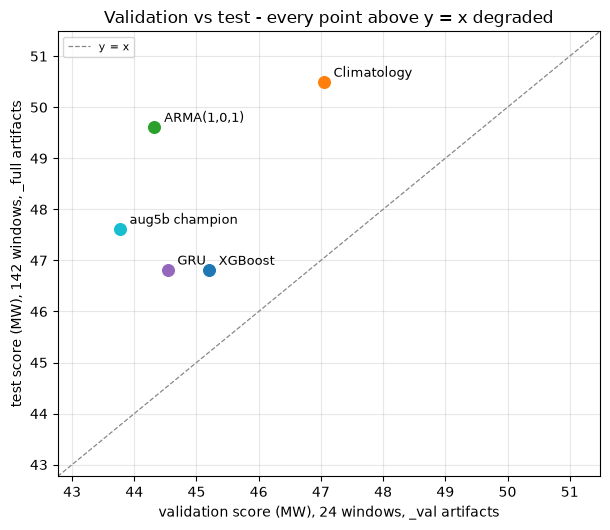

In [31]:
KNOWN = {
    #  model            val      test
    "Climatology":    (47.047, 50.487),
    "ARMA(1,0,1)":    (44.324, 49.605),
    "XGBoost":        (45.200, 46.804),
    "GRU":            (44.537, 46.809),
    "aug5b champion": (43.768, 47.608),
}
# prefer anything measured in this session
for n, r in RESULTS.items():
    if r.get("valid") and n in KNOWN:
        v, t = KNOWN[n]
        KNOWN[n] = (r["competition_score"], t) if SPLIT == "val" else (v, r["competition_score"])

gap = pd.DataFrame([{"model": n, "val_MW": v, "test_MW": t, "gap_MW": round(t - v, 3)}
                    for n, (v, t) in KNOWN.items()]).sort_values("val_MW").reset_index(drop=True)
gap["val_rank"] = gap["val_MW"].rank().astype(int)
gap["test_rank"] = gap["test_MW"].rank().astype(int)
print(gap.to_string(index=False))

n = len(gap)
d = gap["val_rank"] - gap["test_rank"]
rho = 1 - 6 * float((d ** 2).sum()) / (n * (n ** 2 - 1))
print("\nSpearman rho (validation rank vs test rank), n = {}: {:+.2f}".format(n, rho))
print("At n = 5, |rho| would need to be about 0.9 to be distinguishable from chance, so")
print("read this as 'no evidence the ordering transfers', not 'the ordering inverts'.")

fig, ax = plt.subplots(figsize=(6.2, 5.4))
for _, r in gap.iterrows():
    ax.scatter(r["val_MW"], r["test_MW"], s=70, color=COLOURS.get(r["model"], NAVY), zorder=4)
    ax.annotate(r["model"], (r["val_MW"], r["test_MW"]), textcoords="offset points",
                xytext=(7, 4), fontsize=9)
lo = float(min(gap["val_MW"].min(), gap["test_MW"].min())) - 1
hi = float(max(gap["val_MW"].max(), gap["test_MW"].max())) + 1
ax.plot([lo, hi], [lo, hi], color="#888888", lw=0.9, ls="--", label="y = x")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("validation score (MW), 24 windows, _val artifacts")
ax.set_ylabel("test score (MW), 142 windows, _full artifacts")
ax.set_title("Validation vs test - every point above y = x degraded")
ax.legend(fontsize=8); plt.tight_layout(); savefig(fig, "val_vs_test"); plt.show()
# Analysis: every model degrades, but by 1.6 to 5.3 MW -- not a constant offset that can
# be subtracted. ARMA, best on validation, is worst on test; its winning configuration
# (fit_days=30) is the one fitting the shortest, most recent stretch of history, which is
# exactly what you would expect to be season-specific.


### Reproducing outside the notebook

```bash
cd windevolve_sdwpf
python paths.py                                    # verify locations

# validation split
SDWPF_ARIMA_MODEL=baselines/classical/arma_val.joblib \
SDWPF_GBDT_MODEL=baselines/tree/gbdt_val.joblib \
SDWPF_GRU_CHECKPOINTS=baselines/gru/ckpt_val \
  python evaluation/evaluator.py baselines/classical/baseline_arima.py

# test split
SDWPF_ARIMA_MODEL=baselines/classical/arma_full.joblib \
SDWPF_GBDT_MODEL=baselines/tree/gbdt_full.joblib \
SDWPF_GRU_CHECKPOINTS=baselines/gru/ckpt_full \
  python evaluation/competition_score.py baselines/classical/baseline_arima.py
```

Figures for the deck are written to `runs/plots/notebook/<split>/`.
